In [1]:
!pip install lightgbm requests pandas numpy matplotlib scikit-learn

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------------------------------- - 1.3/1.4 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 4.4 MB/s  0:00:00

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 2/2 [lightgbm]



In [3]:
#German Wind Generation Data Loading
file = "time_series_60min_singleindex.csv"

gen = pd.read_csv(
    file,
    usecols=["utc_timestamp", "DE_wind_generation_actual"],
    parse_dates=["utc_timestamp"],
    index_col="utc_timestamp",
)
gen.columns = ["wind_mw"]
gen = gen.loc["2015-01-01":"2020-09-30"]
print(gen.shape)
gen.head()

(50400, 1)


,wind_mw
utc_timestamp,
2015-01-01 00:00:00+00:00,8852.0
2015-01-01 01:00:00+00:00,9054.0
2015-01-01 02:00:00+00:00,9070.0
2015-01-01 03:00:00+00:00,9163.0
2015-01-01 04:00:00+00:00,9231.0


In [4]:
#download the weather data

points = {
    "north_sea": (54.0, 8.0),
    "baltic": (54.3, 12.0),
    "inland_north": (52.5, 9.5),
}

frames = []
for name, (lat, lon) in points.items():
    r = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": lat,
            "longitude": lon,
            "start_date": "2015-01-01",
            "end_date": "2020-09-30",
            "hourly": "wind_speed_100m",
            "wind_speed_unit": "ms",
            "timezone": "UTC",
        },
        timeout=120,
    )
    r.raise_for_status()
    h = r.json()["hourly"]
    df_w = pd.DataFrame({
        "time": pd.to_datetime(h["time"], utc=True),
        f"ws_{name}": h["wind_speed_100m"],
    })
    frames.append(df_w.set_index("time"))

weather = pd.concat(frames, axis=1)
weather.to_csv("weather_wind.csv")
weather.describe()

,ws_north_sea,ws_baltic,ws_inland_north
count,50400.000000,50400.000000,50400.000000
mean,9.329565,8.575741,6.253866
std,4.297557,3.958125,2.865422
min,0.100000,0.000000,0.000000
25%,6.250000,5.700000,4.250000
50%,9.100000,8.320000,6.060000
75%,12.050000,11.130000,7.960000
max,29.060000,28.140000,24.180000


In [5]:
#check data quality

df = gen.join(weather, how="inner")
df = df.asfreq("h")

print("Rows:", len(df))
print("Missing values per column:")
print(df.isna().sum())
print("Zero generation hours:", (df["wind_mw"] == 0).sum())
print("Negative values:", (df["wind_mw"] < 0).sum())
print(df["wind_mw"].describe())

Rows: 50400
Missing values per column:
wind_mw            74
ws_north_sea        0
ws_baltic           0
ws_inland_north     0
dtype: int64
Zero generation hours: 0
Negative values: 0
count    50326.000000
mean     11552.234650
std       9076.350769
min        135.000000
25%       4506.000000
50%       9015.000000
75%      16113.750000
max      46064.000000
Name: wind_mw, dtype: float64


Data quality check

The joined dataset has 50,400 hourly rows from 1 January 2015 to 30 September 2020. The count matches the expected number of hours, so no timestamps are missing.

The wind generation column has 74 missing values, which is about 0.15% of the rows. The three weather columns have none. There are no zero or negative generation values. Generation ranges from 135 MW to 46,064 MW, with a mean of about 11,552 MW and a median of about 9,015 MW. The mean sits above the median, so the data skews toward a few very high output hours.

Next step: check how long the gaps are. Gaps of up to three hours will be filled by interpolation. Longer gaps will be dropped so the model does not train on invented values.

In [6]:
missing = df["wind_mw"].isna()
gap_id = (missing != missing.shift()).cumsum()
gap_lengths = missing.groupby(gap_id).sum()
gap_lengths = gap_lengths[gap_lengths > 0]

print("Number of gaps:", len(gap_lengths))
print("Longest gap (hours):", gap_lengths.max())
print(gap_lengths.value_counts().sort_index())
print(df.index[missing][:10])

Number of gaps: 4
Longest gap (hours): 24
wind_mw
2     1
24    3
Name: count, dtype: int64
DatetimeIndex(['2016-05-31 21:00:00+00:00', '2016-05-31 22:00:00+00:00',
               '2016-05-31 23:00:00+00:00', '2016-06-01 00:00:00+00:00',
               '2016-06-01 01:00:00+00:00', '2016-06-01 02:00:00+00:00',
               '2016-06-01 03:00:00+00:00', '2016-06-01 04:00:00+00:00',
               '2016-06-01 05:00:00+00:00', '2016-06-01 06:00:00+00:00'],
              dtype='datetime64[ns, UTC]', name='utc_timestamp', freq=None)


The gaps are one of 2 hours and three of 24 hours, which adds up to your 74 missing values.

In [7]:
def fill_short_gaps(s, max_len=3):
    missing = s.isna()
    gap_id = (missing != missing.shift()).cumsum()
    gap_size = missing.groupby(gap_id).transform("sum")
    filled = s.interpolate(limit_area="inside")
    return s.where(~(missing & (gap_size <= max_len)), filled)

before = df["wind_mw"].isna().sum()
df["wind_mw"] = fill_short_gaps(df["wind_mw"])
after = df["wind_mw"].isna().sum()

print("Missing before:", before)
print("Missing after:", after)
print("Rows kept in the table:", len(df))

Missing before: 74
Missing after: 72
Rows kept in the table: 50400


The 74 missing generation values fall into four gaps. One lasts 2 hours and three last 24 hours each. The first long gap starts on 31 May 2016 at 21:00 UTC. The 2 hour gap is filled by linear interpolation, since a short gap in a smooth series is low risk. The three 24 hour gaps are left empty and excluded from training and testing. Filling a full day of wind output would mean guessing one of the most variable parts of the series, which would make the scores less trustworthy.

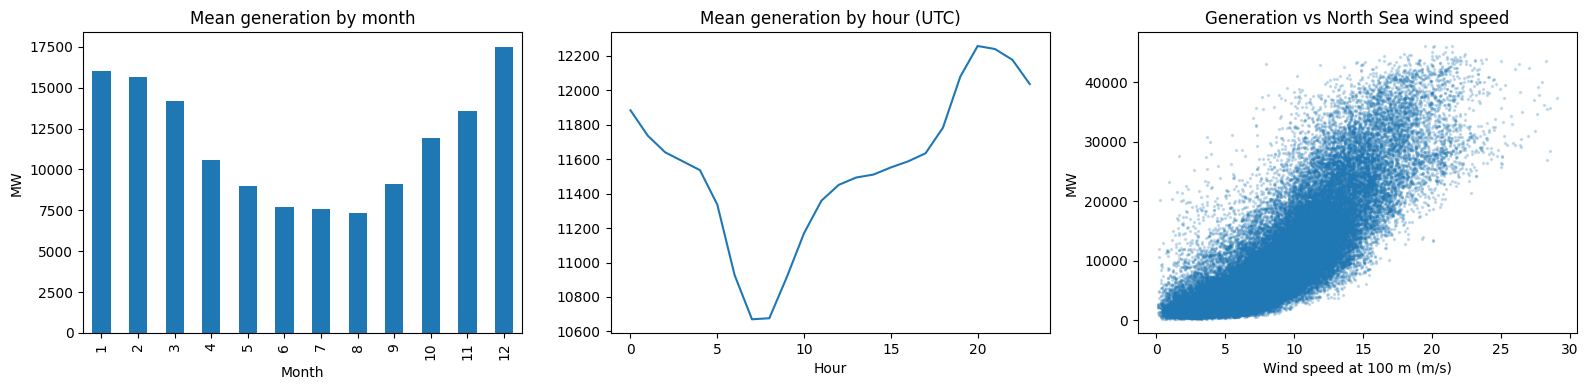

wind_mw            1.00
ws_north_sea       0.81
ws_baltic          0.74
ws_inland_north    0.86
Name: wind_mw, dtype: float64


In [8]:
weather_cols = [c for c in df.columns if c.startswith("ws_")]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df.groupby(df.index.month)["wind_mw"].mean().plot(kind="bar", ax=ax[0])
ax[0].set_title("Mean generation by month")
ax[0].set_xlabel("Month")
ax[0].set_ylabel("MW")

df.groupby(df.index.hour)["wind_mw"].mean().plot(ax=ax[1])
ax[1].set_title("Mean generation by hour (UTC)")
ax[1].set_xlabel("Hour")

ax[2].scatter(df["ws_north_sea"], df["wind_mw"], s=2, alpha=0.2)
ax[2].set_title("Generation vs North Sea wind speed")
ax[2].set_xlabel("Wind speed at 100 m (m/s)")
ax[2].set_ylabel("MW")

plt.tight_layout()
plt.show()

print(df[["wind_mw"] + weather_cols].corr().round(2)["wind_mw"])

Generation correlates with 100 m wind speed at all three points. The inland north point is strongest at 0.86, then the North Sea at 0.81 and the Baltic at 0.74. These are linear correlations. A turbine's output follows a curve that rises with wind speed and then flattens at its rated maximum, so a linear measure understates the real link. This is one reason I use tree-based models.

Mean generation shows a strong seasonal pattern. It is highest in December at about 17,500 MW and in January and February at around 16,000 MW. It is lowest in the summer, at about 7,500 MW in July and August. Winter output is more than double summer output, so month is an important feature.

The daily pattern is much weaker. Mean generation ranges from about 10,700 MW at 07:00 UTC to about 12,200 MW at 20:00 UTC, a difference of roughly 14% of the average. Hour of day is a minor signal compared with season.

The scatter plot shows output rising steeply between about 5 and 15 m/s and flattening near 40,000 MW above about 17 m/s, which matches a turbine power curve. A few points at very high wind speeds sit below the plateau, which is consistent with turbines shutting down in storms. The wide spread at any given wind speed shows that three weather points do not capture the whole country, so I add lagged values and calendar features next.

Two things to check before you move on. The hourly chart's vertical axis starts at 10,600, which makes the daily dip look larger than it is, so keep the 14% figure in your notes. The storm shutdown comment is my reading of a few points in the top right, so keep it only if you see those points yourself.

In [9]:
feat = df.copy()

for c in weather_cols:
    feat[f"{c}_lag1"] = feat[c].shift(1)
    feat[f"{c}_lag24"] = feat[c].shift(24)

feat["wind_mw_lag24"] = feat["wind_mw"].shift(24)
feat["wind_mw_lag168"] = feat["wind_mw"].shift(168)
feat["hour"] = feat.index.hour
feat["month"] = feat.index.month
feat["dayofweek"] = feat.index.dayofweek

rows_before = len(feat)
feat = feat.dropna()
print("Rows before dropping incomplete rows:", rows_before)
print("Rows after:", len(feat))
print("Rows lost:", rows_before - len(feat))

X = feat.drop(columns=["wind_mw"])
y = feat["wind_mw"]

train_mask = feat.index < "2019-01-01"
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]

print("Train rows:", len(X_train), "from", X_train.index.min(), "to", X_train.index.max())
print("Test rows:", len(X_test), "from", X_test.index.min(), "to", X_test.index.max())
print("Number of features:", X.shape[1])
print(list(X.columns))

Rows before dropping incomplete rows: 50400
Rows after: 50016
Rows lost: 384
Train rows: 34680 from 2015-01-08 00:00:00+00:00 to 2018-12-31 23:00:00+00:00
Test rows: 15336 from 2019-01-01 00:00:00+00:00 to 2020-09-30 23:00:00+00:00
Number of features: 14
['ws_north_sea', 'ws_baltic', 'ws_inland_north', 'ws_north_sea_lag1', 'ws_north_sea_lag24', 'ws_baltic_lag1', 'ws_baltic_lag24', 'ws_inland_north_lag1', 'ws_inland_north_lag24', 'wind_mw_lag24', 'wind_mw_lag168', 'hour', 'month', 'dayofweek']


Features and split

I built 14 features: wind speed at three locations, each location's wind speed lagged by 1 and 24 hours, generation lagged by 24 and 168 hours, and hour, month and day of week. Rows with missing values were removed, which cost 384 of 50,400 rows (0.76%). The data is split by time. Training uses 34,680 hours from January 2015 to December 2018. Testing uses 15,336 hours from January 2019 to September 2020. No shuffling was used, so the model never sees the future during training.

In [10]:
def scores(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return round(mae, 1), round(rmse, 1)

results = {}

# Baseline 1: same hour yesterday
pred_naive24 = X_test["wind_mw_lag24"]
results["Same hour yesterday"] = scores(y_test, pred_naive24)

# Baseline 2: average of the same hour over the last 7 days
lags = [df["wind_mw"].shift(24 * k) for k in range(1, 8)]
avg7 = pd.concat(lags, axis=1).mean(axis=1)
pred_avg7 = avg7.loc[y_test.index]
results["7-day same-hour average"] = scores(y_test, pred_avg7)

print("Mean test generation (MW):", round(y_test.mean(), 1))
results

Mean test generation (MW): 14152.1


{'Same hour yesterday': (6890.1, 9173.5),
 '7-day same-hour average': (7220.3, 9269.3)}

Baselines

I set two simple baselines to beat. The first uses generation at the same hour yesterday. The second averages the same hour over the previous seven days. On the test period, the mean generation is 14,152 MW. Same hour yesterday has an MAE of 6,890 MW (48.7% of the mean) and an RMSE of 9,174 MW. The 7-day average has an MAE of 7,220 MW (51.0%) and an RMSE of 9,269 MW. Both are poor, because wind output changes sharply from day to day. Any useful model has to improve on the first.

In [11]:
rf = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results["Random Forest"] = scores(y_test, pred_rf)

print("Random Forest (MAE, RMSE):", results["Random Forest"])
print("Largest training value (MW):", y_train.max())
print("Largest test value (MW):", y_test.max())
print("Largest Random Forest prediction (MW):", round(pred_rf.max(), 1))

Random Forest (MAE, RMSE): (3081.1, 4232.9)
Largest training value (MW): 44629.0
Largest test value (MW): 46064.0
Largest Random Forest prediction (MW): 40934.5


Random Forest

I trained a Random Forest with 200 trees and a minimum leaf size of 5 on the 2015 to 2018 data. On the 2019 to September 2020 test period, it reached an MAE of 3,081 MW (21.8% of mean generation) and an RMSE of 4,233 MW. That is 55.3% lower MAE than the best baseline, same hour yesterday, which scored 6,890 MW. The highest test value was 46,064 MW and the highest training value was 44,629 MW. The model's largest prediction was 40,935 MW, so it under-predicts the highest output hours, as averaging models tend to.

In [14]:
from sklearn.ensemble import HistGradientBoostingRegressor

gbm = HistGradientBoostingRegressor(
    max_iter=600,
    learning_rate=0.05,
    max_leaf_nodes=31,
    early_stopping=False,
    random_state=42,
)
gbm.fit(X_train, y_train)
pred_gbm = gbm.predict(X_test)
results["Gradient Boosting"] = scores(y_test, pred_gbm)

print("Gradient Boosting (MAE, RMSE):", results["Gradient Boosting"])
print("Largest Gradient Boosting prediction (MW):", round(pred_gbm.max(), 1))
print("Mean error, actual minus predicted (MW):")
print("  Random Forest:", round((y_test - pred_rf).mean(), 1))
print("  Gradient Boosting:", round((y_test - pred_gbm).mean(), 1))

Gradient Boosting (MAE, RMSE): (2871.4, 3919.7)
Largest Gradient Boosting prediction (MW): 40505.7
Mean error, actual minus predicted (MW):
  Random Forest: 2353.8
  Gradient Boosting: 1986.2


I trained scikit-learn's HistGradientBoostingRegressor with 600 iterations, a learning rate of 0.05 and up to 31 leaves per tree. Early stopping was turned off so the training data stayed in time order. On the test period it reached an MAE of 2,871 MW (20.3% of mean generation) and an RMSE of 3,920 MW. That is 58.3% lower MAE than the best baseline and 6.8% lower than the Random Forest. The model under-predicts on average by 1,986 MW, which is about 69% of its MAE. The largest prediction was 40,506 MW against a test maximum of 46,064 MW, so it also under-predicts the highest output hours.

In [15]:
check = pd.DataFrame({"actual": y_test, "predicted": pred_gbm}, index=y_test.index)
check["error"] = check["actual"] - check["predicted"]

by_year = check.groupby(check.index.year).agg(
    actual_mean=("actual", "mean"),
    predicted_mean=("predicted", "mean"),
    mean_error=("error", "mean"),
).round(0)
print("Test period by year:")
print(by_year)

print("Mean generation in training years (MW):")
print(y_train.groupby(y_train.index.year).mean().round(0))

Test period by year:
               actual_mean  predicted_mean  mean_error
utc_timestamp                                         
2019               14133.0         12359.0      1774.0
2020               14178.0         11909.0      2269.0
Mean generation in training years (MW):
utc_timestamp
2015     8710.0
2016     8706.0
2017    11720.0
2018    12393.0
Name: wind_mw, dtype: float64


Bias check

The gradient boosting model under-predicts in both test years. The mean error is 1,774 MW in 2019 (12.6% of actual mean generation) and 2,269 MW in 2020 (16.0%). Mean generation in the training years rose from 8,710 MW in 2015 to 12,393 MW in 2018, and the test years averaged about 14,150 MW. The model's average predictions of 12,359 MW and 11,909 MW are close to the 2018 level. This is consistent with growth in installed wind capacity, although a windier period could also play a part. The model learned the relationship between wind speed and output from earlier years, so it under-predicts when the same wind produces more power. Next I add recent generation levels as features to test whether the model can adapt.

In [20]:
roll7 = df["wind_mw"].shift(24).rolling(24 * 7, min_periods=24 * 5).mean()
roll30 = df["wind_mw"].shift(24).rolling(24 * 30, min_periods=24 * 20).mean()

feat2 = feat.copy()
feat2["roll7"] = roll7.reindex(feat2.index)
feat2["roll30"] = roll30.reindex(feat2.index)
feat2 = feat2.dropna()

X2 = feat2.drop(columns=["wind_mw"])
y2 = feat2["wind_mw"]
mask2 = feat2.index < "2019-01-01"
X2_train, y2_train = X2[mask2], y2[mask2]
X2_test, y2_test = X2[~mask2], y2[~mask2]

print("Train rows:", len(X2_train), "Test rows:", len(X2_test))
print("Same test rows as before:", X2_test.index.equals(X_test.index))

gbm2 = HistGradientBoostingRegressor(
    max_iter=600,
    learning_rate=0.05,
    max_leaf_nodes=31,
    early_stopping=False,
    random_state=42,
)
gbm2.fit(X2_train, y2_train)
pred_gbm2 = gbm2.predict(X2_test)

results["Gradient Boosting + level features"] = scores(y2_test, pred_gbm2)
print("MAE, RMSE:", results["Gradient Boosting + level features"])
print("Mean error (MW):", round((y2_test - pred_gbm2).mean(), 1))
print("Largest prediction (MW):", round(pred_gbm2.max(), 1))

Train rows: 34345 Test rows: 15336
Same test rows as before: True
MAE, RMSE: (2632.0, 3560.3)
Mean error (MW): 1478.2
Largest prediction (MW): 40420.4


In [21]:
assert X2_test.index.equals(X_test.index), "Test rows differ, rerun Cell 12"

preds = {
    "Same hour yesterday": np.asarray(pred_naive24),
    "7-day same-hour average": np.asarray(pred_avg7),
    "Random Forest": np.asarray(pred_rf),
    "Gradient Boosting": np.asarray(pred_gbm),
    "Gradient Boosting + level features": np.asarray(pred_gbm2),
}

rows = []
for name, p in preds.items():
    mae = mean_absolute_error(y_test, p)
    rmse = np.sqrt(mean_squared_error(y_test, p))
    bias = (y_test.to_numpy() - p).mean()
    rows.append([name, mae, rmse, bias])

table = pd.DataFrame(rows, columns=["Model", "MAE (MW)", "RMSE (MW)", "Mean error (MW)"]).set_index("Model")
table["MAE % of mean"] = (table["MAE (MW)"] / y_test.mean() * 100).round(1)

best_baseline = table.loc[["Same hour yesterday", "7-day same-hour average"], "MAE (MW)"].min()
table["MAE gain vs best baseline %"] = ((1 - table["MAE (MW)"] / best_baseline) * 100).round(1)

best_model = table["MAE (MW)"].idxmin()
print("Best model by MAE:", best_model)
table.round(1)

Best model by MAE: Gradient Boosting + level features


,MAE (MW),RMSE (MW),Mean error (MW),MAE % of mean,MAE gain vs best baseline %
Model,,,,,
Same hour yesterday,6890.1,9173.5,-7.6,48.7,0.0
7-day same-hour average,7220.3,9269.3,-57.2,51.0,-4.8
Random Forest,3081.1,4232.9,2353.8,21.8,55.3
Gradient Boosting,2871.4,3919.7,1986.2,20.3,58.3
Gradient Boosting + level features,2632.0,3560.3,1478.2,18.6,61.8


Results

I compared five approaches on the same 15,336 test hours from January 2019 to September 2020. Two simple baselines scored an MAE of 6,890 MW (same hour yesterday) and 7,220 MW (7-day same-hour average). A Random Forest reached 3,081 MW and gradient boosting reached 2,871 MW. Adding two features for recent generation level, a 7-day and a 30-day trailing mean shifted by 24 hours, brought the MAE to 2,632 MW (18.6% of mean generation) and the RMSE to 3,560 MW. That is 61.8% lower MAE than the best baseline.

The final model still under-predicts by 1,478 MW on average (10.4% of mean test generation). The recent-level features cut the bias by about a quarter, but did not remove it.